# Fraud Radar · 01 — Exploratory Data Analysis

**Goal:** understand how fraud behaves in real e-commerce payments before building any model.

**Data:** [IEEE-CIS Fraud Detection](https://www.kaggle.com/competitions/ieee-fraud-detection/data) (Vesta Corporation) · `train_transaction.csv` + `train_identity.csv`

**What this notebook does**
1. Loads both tables with a memory-friendly approach and joins them by `TransactionID`
2. Measures the fraud rate (class imbalance)
3. Explores fraud by **time**, **amount**, **product**, **card**, **email domain** and **device**
4. Checks missing values and identity coverage
5. Defines the **time-based split** that the model will use
6. Saves a clean, merged file for the modeling notebook

## 0. Setup

In [22]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Paths (this notebook lives in /notebook, data in /dataset/raw)
RAW = Path("../dataset/raw")
PROCESSED = Path("../dataset/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

# Consistent colors for the whole project
FRAUD, LEGIT, ACCENT, MUTED = "#dc5a96", "#2c9fc4", "#7b8fd6", "#8e9ac8"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 13,
})

## 1. Load the data

The transaction table has ~590k rows and ~394 columns. Reading every number as `float64` can take several GB of RAM,
so we read a small sample first, detect which columns are numeric, and load them as `float32` (half the memory).

In [23]:
def read_compact(path: Path) -> pd.DataFrame:
    sample = pd.read_csv(path, nrows=5_000)
    dtypes = {}
    for col in sample.columns:
        if col in ("TransactionID", "TransactionDT"):
            dtypes[col] = "int64"
        elif col == "isFraud":
            dtypes[col] = "int8"
        elif pd.api.types.is_numeric_dtype(sample[col]):
            dtypes[col] = "float32"
        else:
            dtypes[col] = "category"
    return pd.read_csv(path, dtype=dtypes)

tx = read_compact(RAW / "train_transaction.csv")
idn = read_compact(RAW / "train_identity.csv")

print(f"Transactions: {tx.shape[0]:,} rows × {tx.shape[1]} columns · {tx.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Identity:     {idn.shape[0]:,} rows × {idn.shape[1]} columns · {idn.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Transactions: 590,540 rows × 394 columns · 0.91 GB
Identity:     144,233 rows × 41 columns · 0.02 GB


### Join both tables
`transaction` and `identity` are **not** a split: they describe the **same** payments (payment data vs. device/identity data).
Not every transaction has identity information, so we use a **left join** to keep all transactions.

In [24]:
df = tx.merge(idn, on="TransactionID", how="left").copy()
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"]).astype("int8")
del tx, idn

assert df["TransactionID"].is_unique, "Duplicated transactions after the join"
print(f"Merged: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Merged: 590,540 rows × 435 columns


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,...,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,has_identity
0,2987000,0,86400,68.5000,W,"13,926.0000",NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,NaN,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2987001,0,86401,29.0000,W,"2,755.0000",404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2987002,0,86469,59.0000,W,"4,663.0000",490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,NaN,outlook.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,2987003,0,86499,50.0000,W,"18,132.0000",567.0000,150.0000,mastercard,117.0000,debit,476.0000,87.0000,NaN,NaN,yahoo.com,NaN,2.0000,5.0000,0.0000,0.0000,0.0000,4.0000,0.0000,0.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,2987004,0,86506,50.0000,H,"4,497.0000",514.0000,150.0000,mastercard,102.0000,credit,420.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,166.0000,NaN,542.0000,144.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0000,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,1


## 2. How rare is fraud?

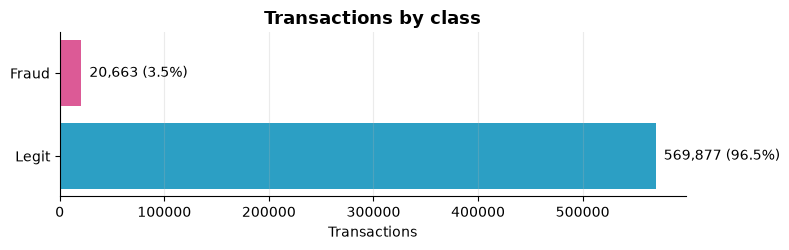

Fraud rate: 3.50% → a model that always says 'legit' would be 96.5% accurate and useless.


In [25]:
counts = df["isFraud"].value_counts().sort_index()
rate = df["isFraud"].mean()

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(["Legit", "Fraud"], counts.values, color=[LEGIT, FRAUD])
for i, v in enumerate(counts.values):
    ax.text(v, i, f"  {v:,} ({v / counts.sum():.1%})", va="center")
ax.set_title("Transactions by class")
ax.set_xlabel("Transactions")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print(f"Fraud rate: {rate:.2%} → a model that always says 'legit' would be {1 - rate:.1%} accurate and useless.")

## 3. Time

`TransactionDT` is a **time offset in seconds** from an undisclosed reference date (not a real timestamp).
We derive the **day** and the **hour of day** from it.

Time span covered: 182 days


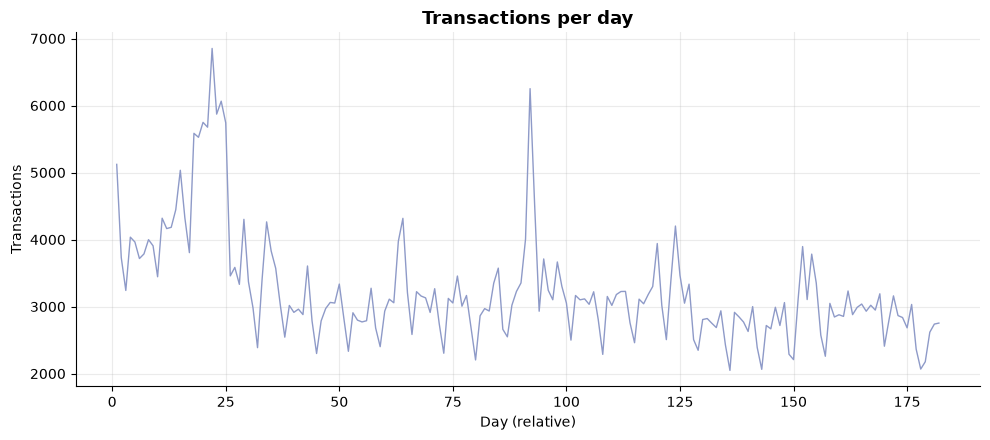

In [26]:
df["day"] = (df["TransactionDT"] // 86_400).astype("int32")
df["hour"] = ((df["TransactionDT"] // 3_600) % 24).astype("int8")

print(f"Time span covered: {df['day'].max() - df['day'].min() + 1} days")

daily = df.groupby("day").agg(transactions=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
fig, ax1 = plt.subplots()
ax1.plot(daily.index, daily["transactions"], color=MUTED, lw=1)
ax1.set_title("Transactions per day")
ax1.set_xlabel("Day (relative)"); ax1.set_ylabel("Transactions")
plt.tight_layout(); plt.show()

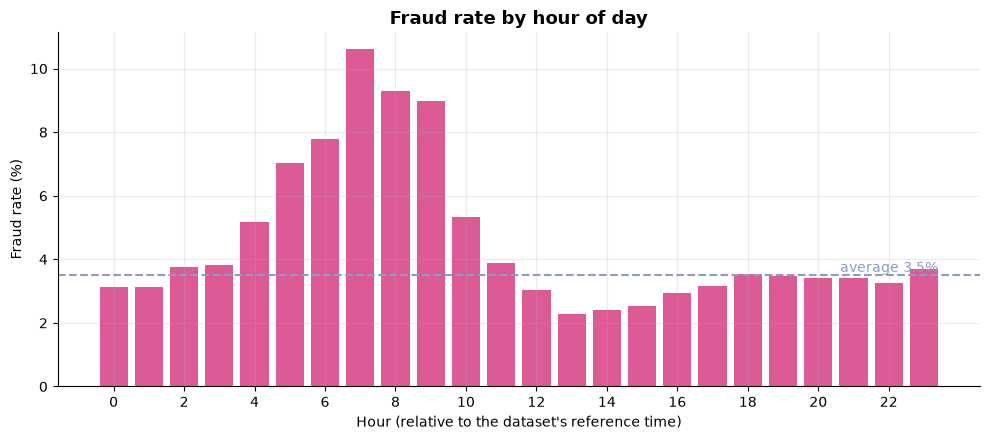

Highest fraud rate at hour 7: 10.61% (3.0× the average)


In [27]:
by_hour = df.groupby("hour")["isFraud"].agg(["mean", "size"])

fig, ax = plt.subplots()
ax.bar(by_hour.index, by_hour["mean"] * 100, color=FRAUD)
ax.axhline(rate * 100, color=MUTED, ls="--", lw=1.5)
ax.text(23.4, rate * 100, f" average {rate:.1%}", va="bottom", ha="right", color=MUTED)
ax.set_title("Fraud rate by hour of day")
ax.set_xlabel("Hour (relative to the dataset's reference time)"); ax.set_ylabel("Fraud rate (%)")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

peak = by_hour["mean"].idxmax()
print(f"Highest fraud rate at hour {peak}: {by_hour.loc[peak, 'mean']:.2%} ({by_hour.loc[peak, 'mean'] / rate:.1f}× the average)")

## 4. Transaction amount

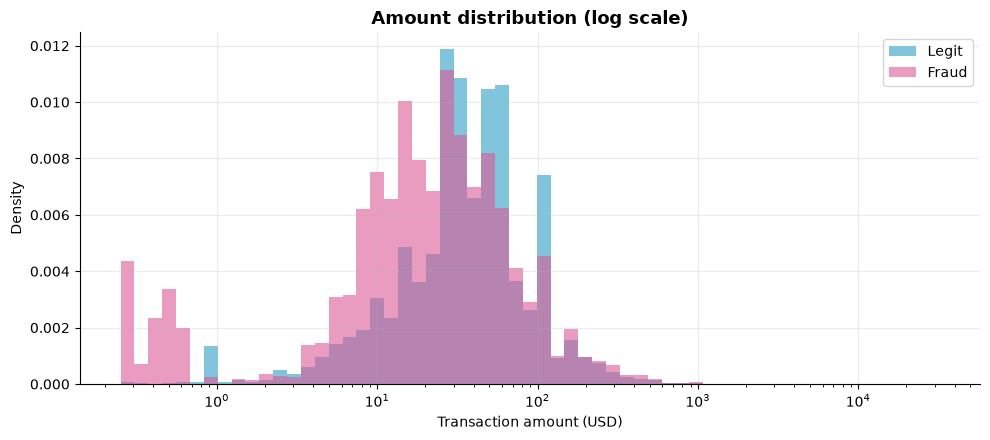

               count     mean      std    min     25%     50%      75%  \
isFraud                                                                  
Legit   569,877.0000 134.5117 239.3951 0.2510 43.9700 68.5000 120.0000   
Fraud    20,663.0000 149.2448 232.2122 0.2920 35.0440 75.0000 161.0000   

             95%         max  
isFraud                       
Legit   435.0000 31,937.3906  
Fraud   500.0000  5,191.0000  


In [28]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(max(df["TransactionAmt"].min(), 0.1)), np.log10(df["TransactionAmt"].max()), 60)
ax.hist(df.loc[df.isFraud == 0, "TransactionAmt"], bins=bins, density=True, alpha=0.6, color=LEGIT, label="Legit")
ax.hist(df.loc[df.isFraud == 1, "TransactionAmt"], bins=bins, density=True, alpha=0.6, color=FRAUD, label="Fraud")
ax.set_xscale("log")
ax.set_title("Amount distribution (log scale)")
ax.set_xlabel("Transaction amount (USD)"); ax.set_ylabel("Density")
ax.legend()
plt.tight_layout(); plt.show()

print(df.groupby("isFraud")["TransactionAmt"].describe(percentiles=[.25, .5, .75, .95]).rename(index={0: "Legit", 1: "Fraud"}))

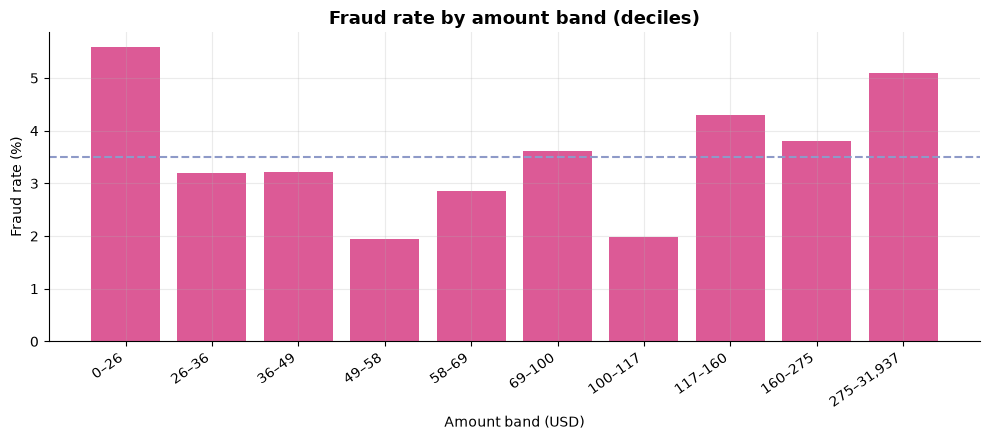

In [29]:
amount_bands = pd.qcut(df["TransactionAmt"], q=10, duplicates="drop")
by_amount = df.groupby(amount_bands, observed=True)["isFraud"].mean() * 100

fig, ax = plt.subplots()
ax.bar(range(len(by_amount)), by_amount.values, color=FRAUD)
ax.axhline(rate * 100, color=MUTED, ls="--", lw=1.5)
ax.set_xticks(range(len(by_amount)))
ax.set_xticklabels([f"{i.left:,.0f}–{i.right:,.0f}" for i in by_amount.index], rotation=35, ha="right")
ax.set_title("Fraud rate by amount band (deciles)")
ax.set_xlabel("Amount band (USD)"); ax.set_ylabel("Fraud rate (%)")
plt.tight_layout(); plt.show()

## 5. Categorical features

For each feature we show **two things side by side**: how many transactions fall in each category (volume)
and the **fraud rate** of that category. A category is interesting when its fraud rate is far from the average
**and** it has enough volume to matter.

In [30]:
def fraud_profile(col: str, top: int = 10, title: str | None = None) -> pd.DataFrame:
    data = df[col].astype("object").fillna("missing")
    stats = (pd.DataFrame({"value": data, "isFraud": df["isFraud"]})
               .groupby("value")["isFraud"].agg(transactions="size", fraud_rate="mean")
               .sort_values("transactions", ascending=False).head(top)
               .sort_values("fraud_rate"))

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 0.45 * len(stats) + 1.6), sharey=True)
    a1.barh(stats.index.astype(str), stats["transactions"], color=MUTED)
    a1.set_title("Volume"); a1.set_xlabel("Transactions"); a1.grid(axis="y", visible=False)
    a2.barh(stats.index.astype(str), stats["fraud_rate"] * 100, color=FRAUD)
    a2.axvline(rate * 100, color=MUTED, ls="--", lw=1.5)
    a2.set_title("Fraud rate"); a2.set_xlabel("%"); a2.grid(axis="y", visible=False)
    fig.suptitle(title or col, fontweight="bold")
    plt.tight_layout(); plt.show()
    return stats.sort_values("fraud_rate", ascending=False)

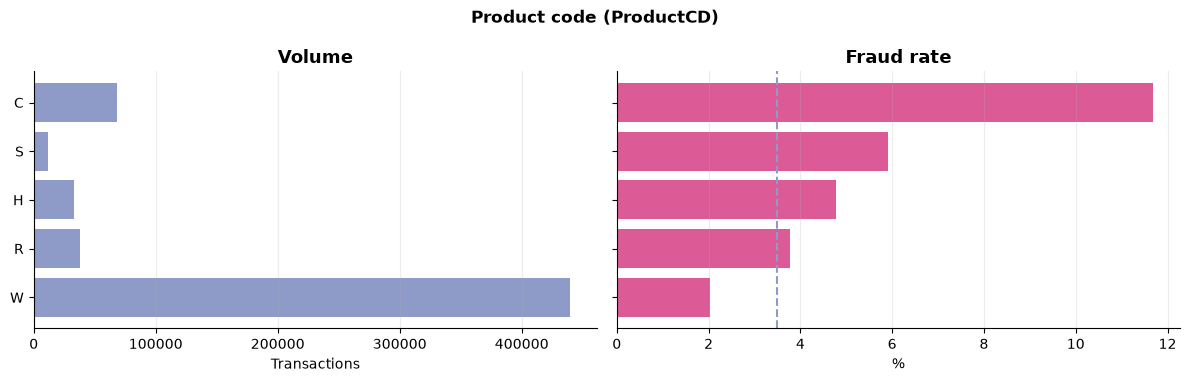

,transactions,fraud_rate
value,,
C,68519,0.1169
S,11628,0.0590
H,33024,0.0477
R,37699,0.0378
W,439670,0.0204


In [31]:
fraud_profile("ProductCD", title="Product code (ProductCD)")

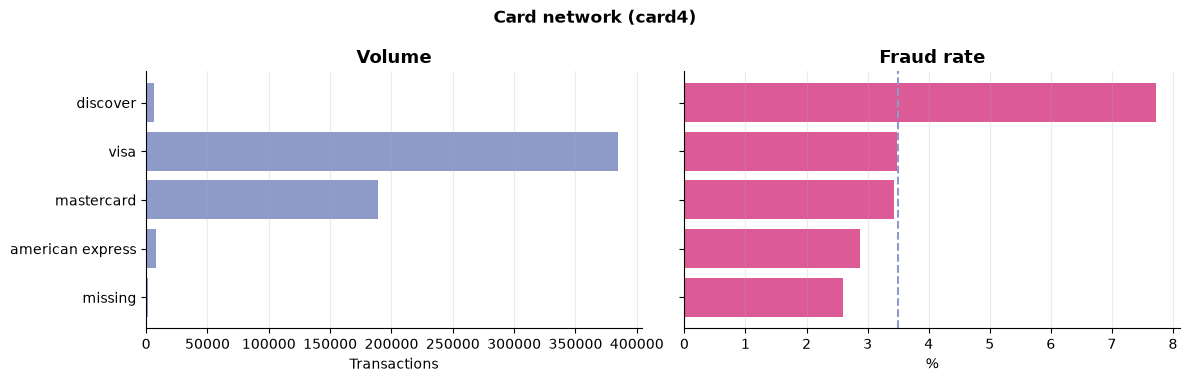

,transactions,fraud_rate
value,,
discover,6651,0.0773
visa,384767,0.0348
mastercard,189217,0.0343
american express,8328,0.0287
missing,1577,0.0260


In [32]:
fraud_profile("card4", title="Card network (card4)")

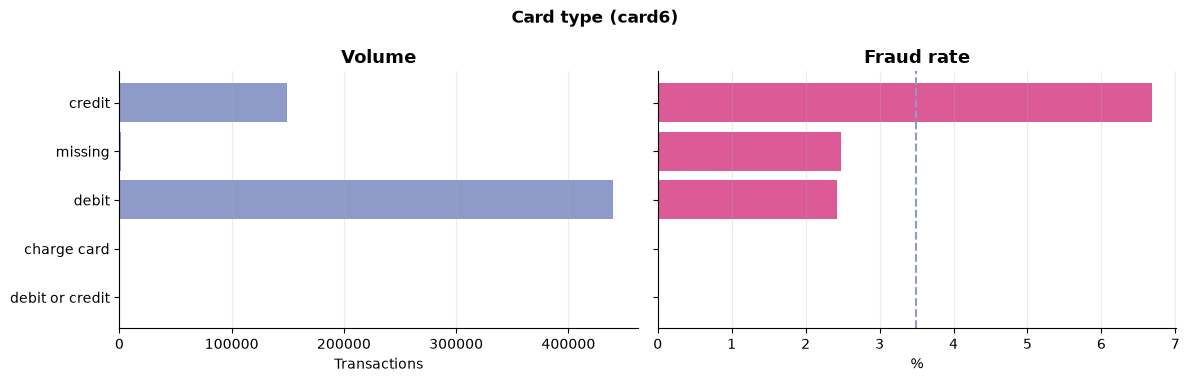

,transactions,fraud_rate
value,,
credit,148986,0.0668
missing,1571,0.0248
debit,439938,0.0243
debit or credit,30,0.0000
charge card,15,0.0000


In [33]:
fraud_profile("card6", title="Card type (card6)")

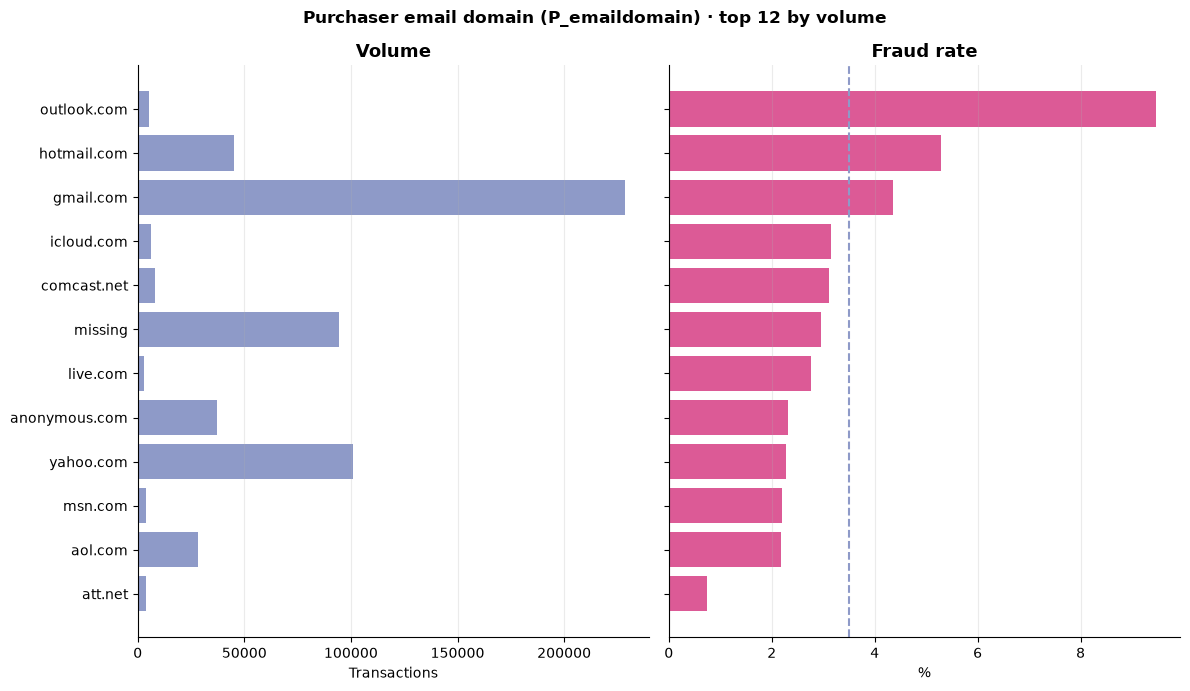

,transactions,fraud_rate
value,,
outlook.com,5096,0.0946
hotmail.com,45250,0.0530
gmail.com,228355,0.0435
icloud.com,6267,0.0314
comcast.net,7888,0.0312
missing,94456,0.0295
live.com,3041,0.0276
anonymous.com,36998,0.0232
yahoo.com,100934,0.0228


In [34]:
fraud_profile("P_emaildomain", top=12, title="Purchaser email domain (P_emaildomain) · top 12 by volume")

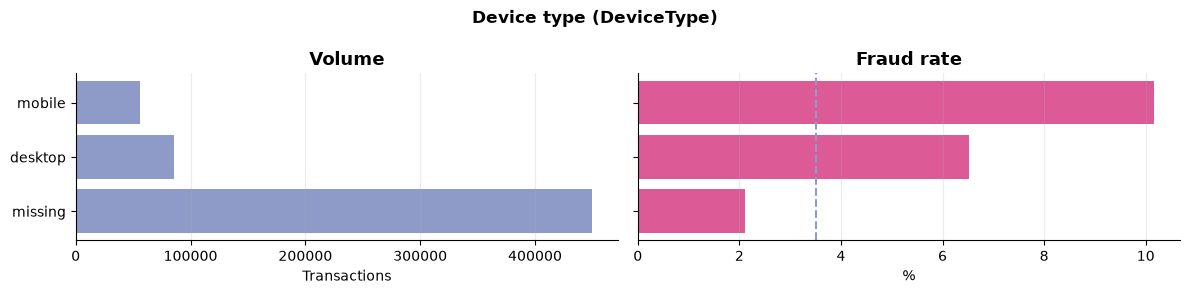

,transactions,fraud_rate
value,,
mobile,55645,0.1017
desktop,85165,0.0652
missing,449730,0.0210


In [35]:
fraud_profile("DeviceType", title="Device type (DeviceType)")

## 6. Missing values

IEEE-CIS has many anonymized column families (`C`, `D`, `M`, `V`, `id_`). Many of them are mostly empty.
Missingness is not just noise here: **whether a value is missing can itself be a signal**.

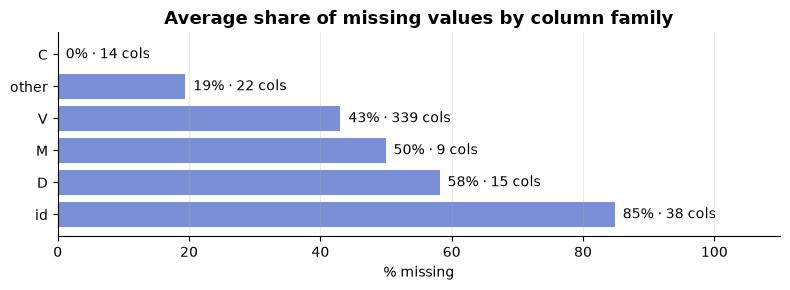

Columns with more than 90% missing values: 12 of 437


In [36]:
def family(col: str) -> str:
    for prefix in ("id_", "V", "C", "D", "M"):
        if col.startswith(prefix) and col[len(prefix):].replace("_", "").isdigit():
            return prefix.rstrip("_") if prefix != "id_" else "id"
    return "other"

missing = df.isna().mean().rename("missing_share").to_frame()
missing["family"] = [family(c) for c in missing.index]
summary = (missing.groupby("family")["missing_share"]
                  .agg(columns="size", avg_missing="mean")
                  .sort_values("avg_missing", ascending=False))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(summary.index, summary["avg_missing"] * 100, color=ACCENT)
for i, (n, v) in enumerate(zip(summary["columns"], summary["avg_missing"])):
    ax.text(v * 100, i, f"  {v:.0%} · {n} cols", va="center")
ax.set_title("Average share of missing values by column family")
ax.set_xlabel("% missing"); ax.set_xlim(0, 110); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print(f"Columns with more than 90% missing values: {(missing['missing_share'] > 0.9).sum()} of {len(missing)}")

## 7. Identity coverage

In [37]:
cov = df.groupby("has_identity")["isFraud"].agg(transactions="size", fraud_rate="mean").rename(index={0: "No identity data", 1: "Has identity data"})
print(cov)
ratio = cov.loc["Has identity data", "fraud_rate"] / cov.loc["No identity data", "fraud_rate"]
print(f"\nTransactions with identity data are {ratio:.1f}× as likely to be fraud.")

                   transactions  fraud_rate
has_identity                               
No identity data         446307      0.0209
Has identity data        144233      0.0785

Transactions with identity data are 3.7× as likely to be fraud.


## 8. Time-based split

The test files from Kaggle have **no labels**, so we create our own validation set from the training data.
We split **by time** (first ~80% of the timeline to train, last ~20% to validate) because in real life the model
always scores **future** transactions. A random split would mix past and future and make results look better than they are.

In [38]:
SPLIT_QUANTILE = 0.80
split_dt = df["TransactionDT"].quantile(SPLIT_QUANTILE)
df["split"] = np.where(df["TransactionDT"] <= split_dt, "train", "valid")

split_stats = df.groupby("split").agg(
    transactions=("isFraud", "size"), fraud_rate=("isFraud", "mean"),
    first_day=("day", "min"), last_day=("day", "max"),
)
print(split_stats)

# Cards that appear in both periods (card1 is an anonymized card identifier)
train_cards = set(df.loc[df.split == "train", "card1"].dropna())
valid_cards = df.loc[df.split == "valid", "card1"]
print(f"\nValidation transactions whose card1 was already seen in train: {valid_cards.isin(train_cards).mean():.1%}")

       transactions  fraud_rate  first_day  last_day
split                                               
train        472432      0.0351          1       141
valid        118108      0.0344        141       182

Validation transactions whose card1 was already seen in train: 98.9%


## 9. Save for the modeling notebook

In [39]:
out = PROCESSED / "train_merged.pkl"
df.to_pickle(out)
print(f"Saved {df.shape[0]:,} rows × {df.shape[1]} columns → {out}")

Saved 590,540 rows × 438 columns → ../dataset/processed/train_merged.pkl


## 10. Key findings

The cell below prints the main numbers from this notebook so they can be copied into the README.
After running it, write 3–5 short conclusions here in your own words.

In [40]:
top_product = df.groupby("ProductCD", observed=True)["isFraud"].mean().sort_values(ascending=False)
top_device = df.groupby(df["DeviceType"].astype("object").fillna("missing"))["isFraud"].mean().sort_values(ascending=False)

print(f"• Fraud rate: {rate:.2%} of {len(df):,} transactions")
print(f"• Time span: {df['day'].max() - df['day'].min() + 1} days · split at day {int(split_dt // 86_400)}")
print(f"• Product with the highest fraud rate: {top_product.index[0]} ({top_product.iloc[0]:.2%})")
print(f"• Device type with the highest fraud rate: {top_device.index[0]} ({top_device.iloc[0]:.2%})")
print(f"• Median amount — legit: ${df.loc[df.isFraud == 0, 'TransactionAmt'].median():,.2f} · fraud: ${df.loc[df.isFraud == 1, 'TransactionAmt'].median():,.2f}")
print(f"• Columns with >90% missing values: {(missing['missing_share'] > 0.9).sum()}")

• Fraud rate: 3.50% of 590,540 transactions
• Time span: 182 days · split at day 141
• Product with the highest fraud rate: C (11.69%)
• Device type with the highest fraud rate: mobile (10.17%)
• Median amount — legit: $68.50 · fraud: $75.00
• Columns with >90% missing values: 12


## 10. Key findings

- **Fraud is rare but not negligible:** 3.50% of 590,540 transactions (20,663 frauds), so accuracy is not a useful metric.
- **Card testing pattern:** a cluster of fraudulent transactions below $1 USD barely appears among legitimate ones — a classic sign of fraudsters testing stolen cards.
- **Riskiest segments:** product **C** (11.7%), **credit** cards (6.7% vs. 2.4% for debit), **Discover** (7.7%), **outlook.com** emails (9.5%) and **mobile** devices (10.2%).
- **Identity data matters:** transactions with identity/device information are **3.7×** as likely to be fraud.
- **Time pattern:** fraud peaks around relative hour 7 (10.6%, 3× the average).
- **Leakage risk:** 98.9% of validation transactions use a card already seen in training, so the model will also be evaluated on unseen cards.